In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.optimize import curve_fit
from numba import jit
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib import cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes# plt.rcParams.update({'font.size': 20})


plt.rcParams.update({
    "text.usetex": True,  # Use LaTeX for text rendering
    "font.family": "serif",  # Match LaTeX font
    "font.size": 14,        # Adjust font size
    "axes.labelsize": 16,   # Axis labels size
    "legend.fontsize": 12,  # Legend font size
    "xtick.labelsize": 12,  # X-axis tick size
    "ytick.labelsize": 12,  # Y-axis tick size
})

alphagrid = 0.4

# Figure 1

In [2]:
### Hebb rule
Nloads = [100,200,400,800,1600]
Cycles = 1
tao = 1.
Instances = 50
Dreams = 0
BatchFrac = 1.0
A = 10000000
loads = [0.02,0.04,0.06,0.08,0.10,0.12,0.14,0.16,0.18,0.20,0.25,0.3,0.4]
RecRateHebbUnclipped = np.zeros((len(Nloads),len(loads),Cycles)) 
MaxRecRateHebbUnclipped = np.zeros((len(Nloads),len(loads))) 
for i,Nload in enumerate(Nloads):
    for j,alpha in enumerate(loads):
        Batches = round(BatchFrac * alpha * Nload)
        RecRateHebbUnclipped[i,j,:] = np.load(f"data/UnclippedHebb/Recognition2percentGeneral_N_{Nload}_load_{alpha:.3f}_Dreams_{Dreams}_Batches_{Batches}_taod_{tao:.2f}_taol_{tao:.2f}_Cycles_{Cycles}_Ninstances_{Instances}_clippedA{A:.2f}.npz")['matrix']
        MaxRecRateHebbUnclipped[i,j] = RecRateHebbUnclipped[i,j,0]
A=0.4
RecRateHebbClipped = np.zeros((len(Nloads),len(loads),Cycles)) 
MaxRecRateHebbClipped = np.zeros((len(Nloads),len(loads))) 
for i,Nload in enumerate(Nloads):
    for j,alpha in enumerate(loads):
        Batches = round(BatchFrac * alpha * Nload)
        RecRateHebbClipped[i,j,:] = np.load(f"data/ClippedHebb/Recognition2percentGeneral_N_{Nload}_load_{alpha:.3f}_Dreams_{Dreams}_Batches_{Batches}_taod_{tao:.2f}_taol_{tao:.2f}_Cycles_{Cycles}_Ninstances_{Instances}_clippedA{A:.2f}.npz")['matrix']
        MaxRecRateHebbClipped[i,j] = RecRateHebbClipped[i,j,0]

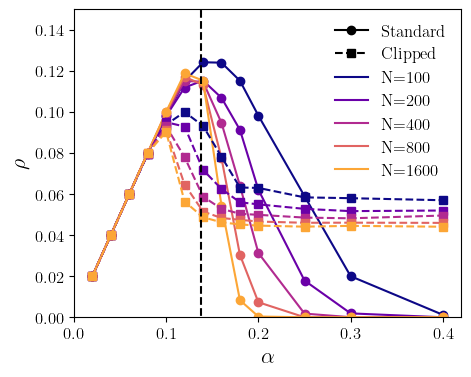

In [3]:
colors = cm.plasma(np.linspace(0, 1, 6))
fig, ax = plt.subplots(1, 1, figsize=(5, 4), sharex=False)

ax.plot(loads,MaxRecRateHebbUnclipped[0,:],marker='o', color=colors[0], label="")
ax.plot(loads,MaxRecRateHebbUnclipped[1,:],marker='o', color=colors[1], label="")
ax.plot(loads,MaxRecRateHebbUnclipped[2,:],marker='o', color=colors[2], label="")
ax.plot(loads,MaxRecRateHebbUnclipped[3,:],marker='o', color=colors[3], label="")
ax.plot(loads,MaxRecRateHebbUnclipped[4,:],marker='o', color=colors[4], label="")
ax.plot(loads,MaxRecRateHebbClipped[0,:],marker='s', linestyle="dashed", color=colors[0], label="")
ax.plot(loads,MaxRecRateHebbClipped[1,:],marker='s', linestyle="dashed", color=colors[1], label="")
ax.plot(loads,MaxRecRateHebbClipped[2,:],marker='s', linestyle="dashed", color=colors[2], label="")
ax.plot(loads,MaxRecRateHebbClipped[3,:],marker='s', linestyle="dashed", color=colors[3], label="")
ax.plot(loads,MaxRecRateHebbClipped[4,:],marker='s', linestyle="dashed", color=colors[4], label="")
ax.plot([],[], marker='o', color='black', label="Standard")
ax.plot([],[],marker='s', color='black', linestyle="dashed", label="Clipped")
ax.plot([],[], color=colors[0], label="N=100")
ax.plot([],[], color=colors[1], label="N=200")
ax.plot([],[], color=colors[2], label="N=400")
ax.plot([],[], color=colors[3], label="N=800")
ax.plot([],[], color=colors[4], label="N=1600")
ax.set_ylim(0,0.15)
ax.set_xlim(0,0.42)
ax.legend(frameon=False)
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"$\rho$")
ax.vlines(0.138,0.8,0.0,linestyles='--',color='black')

plt.savefig("figures/figure1.pdf", format="pdf", bbox_inches="tight") 

# Figure 2

In [4]:
### Dreaming rule
Nload = 200
Cycles = 1
taol = 1.
taod = 100.
Instances = 50
BatchFrac = 1.0
DreamFrac = 1.0
A = 10000000
loads_unclipped = [0.02,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.72,0.74,0.76,0.78,0.8,0.82,0.84,0.86,0.88,0.9,1.0]
Dreams_unclipped = round(DreamFrac*taod*Nload)
RecRateUnclippedDreaming = np.zeros((len(loads_unclipped),Dreams_unclipped))
for j,alpha in enumerate(loads_unclipped):
    Batches = round(BatchFrac * alpha * Nload)
    RecRateUnclippedDreaming[j,:] = np.load(f"data/UnclippedDreaming/Recognition2percentGeneral_N_{Nload}_load_{alpha:.3f}_Dreams_{Dreams_unclipped}_Batches_{Batches}_taod_{taod:.2f}_taol_{taol:.2f}_Cycles_{Cycles}_Ninstances_{Instances}_clippedA{A:.2f}.npz")['matrix']
A=0.4
loads_clipped = [0.02,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.4]
DreamFrac = 0.3
MaxRecRateDreamingClipped = np.zeros((len(Nloads),len(loads_clipped))) 
Dreams_clipped = round(DreamFrac*taod*Nload)
RecRateClippedDreaming = np.zeros((len(loads_clipped),Dreams_clipped))
for j,alpha in enumerate(loads_clipped):
    Batches = round(BatchFrac * alpha * Nload)
    RecRateClippedDreaming[j,:] = np.load(f"data/ClippedDreaming/Recognition2percentGeneral_N_{Nload}_load_{alpha:.3f}_Dreams_{Dreams_clipped}_Batches_{Batches}_taod_{taod:.2f}_taol_{taol:.2f}_Cycles_{Cycles}_Ninstances_{Instances}_clippedA{A:.2f}.npz")['matrix']

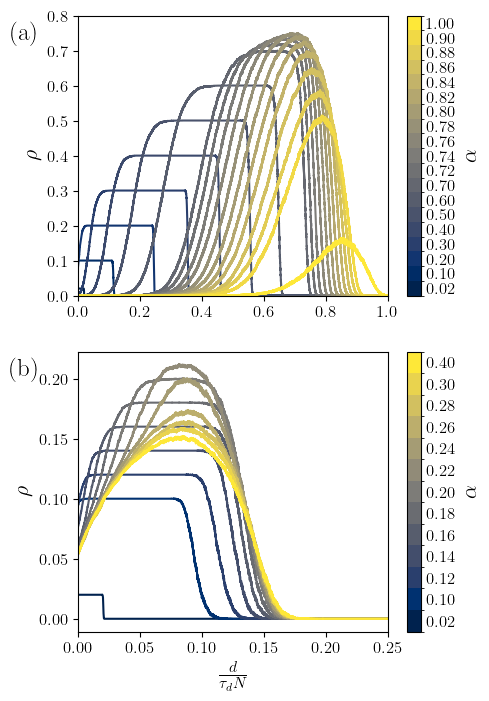

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(5, 8), sharex=False)

ax = axes[0]
ax.text(
    -0.12, 0.98, r"\textrm{(a)}",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=18
)

cmap = cm.cividis
colors = cmap(np.linspace(0, 1, len(loads_unclipped)))         # one color per load
cmap_discrete = ListedColormap(colors)
bounds = np.arange(len(loads_unclipped)+1)
norm = BoundaryNorm(bounds, cmap_discrete.N)

########################################################
####################### PANEL A
########################################################

for i,alpha in enumerate(loads_unclipped):
    # ax.plot(RecRateUnclippedDreaming[i,:], color=colors[i], label = fr"$\alpha = {alpha}$")
    x = np.arange(Dreams_unclipped)/(Nload*taod)
    ax.plot(x,RecRateUnclippedDreaming[i,:], color=colors[i], label = fr"$\alpha = {alpha}$")
# ax.set_xlabel(r"$\frac{d}{\tau_d N}$")
ax.set_ylabel(r"$\rho$")
ax.set_ylim(0,0.8)
ax.set_xlim(0,1.0)

# --- discrete colorbar ---
cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap_discrete),
    ax=ax,
    ticks=np.arange(len(loads_unclipped)) + 0.5      # center ticks
)

# set tick labels to actual alpha values
cbar.ax.tick_params(length=0)
cbar.ax.set_yticklabels([f"{a:.2f}" for a in loads_unclipped])
cbar.set_label(r"$\alpha$")

########################################################
####################### PANEL B
########################################################

ax = axes[1]
ax.text(
    -0.12, 0.98, r"\textrm{(b)}",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=18
)

cmap = cm.cividis
colors = cmap(np.linspace(0, 1, len(loads_clipped)))         # one color per load
cmap_discrete = ListedColormap(colors)
bounds = np.arange(len(loads_clipped)+1)
norm = BoundaryNorm(bounds, cmap_discrete.N)

for i,alpha in enumerate(loads_clipped):
    # ax.plot(RecRateClippedDreaming[i,:], color=colors[i], label = fr"$\alpha = {alpha}$")
    x = np.arange(Dreams_clipped)/(Nload*taod)
    ax.plot(x,RecRateClippedDreaming[i,:], color=colors[i], label = fr"$\alpha = {alpha}$")
ax.set_xlabel(r"$\frac{d}{\tau_d N}$")
ax.set_ylabel(r"$\rho$")
ax.set_xlim(0,0.25)

# --- discrete colorbar ---
cbar = fig.colorbar(
    cm.ScalarMappable(norm=norm, cmap=cmap_discrete),
    ax=ax,
    ticks=np.arange(len(loads_clipped)) + 0.5      # center ticks
)

# set tick labels to actual alpha values
cbar.ax.tick_params(length=0)
cbar.ax.set_yticklabels([f"{a:.2f}" for a in loads_clipped])
cbar.set_label(r"$\alpha$")
plt.savefig("figures/figure2.pdf", format="pdf", bbox_inches="tight")

# Figure 3

In [6]:
### Dreaming rule
Nloads = [100,200,400,800,1600]
Cycles = 1
taol = 1.
taod = 100.
Instances = 50
BatchFrac = 1.0
DreamFrac = 1.0
A = 10000000
loads_unclipped = [0.02,0.1,0.2,0.3,0.4,0.5,0.6,0.65,0.7,0.72,0.74,0.76,0.78,0.8,0.82,0.84,0.86,0.88,0.9,0.95,1.0,1.1,1.2]
MaxRecRateDreamingUnclipped = np.zeros((len(Nloads),len(loads_unclipped))) 
for i,Nload in enumerate(Nloads):
    Dreams = round(DreamFrac*taod*Nload)
    for j,alpha in enumerate(loads_unclipped):
        Batches = round(BatchFrac * alpha * Nload)
        RecRate = np.load(f"data/UnclippedDreaming_undersample/Recognition2percentGeneral_N_{Nload}_load_{alpha:.3f}_Dreams_{Dreams}_Batches_{Batches}_taod_{taod:.2f}_taol_{taol:.2f}_Cycles_{Cycles}_Ninstances_{Instances}_clippedA{A:.2f}.npz")['matrix']
        MaxRecRateDreamingUnclipped[i,j] = np.max(RecRate)
A=0.4
loads_clipped = [0.02,0.1,0.12,0.14,0.16,0.18,0.2,0.22,0.24,0.26,0.28,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2]
DreamFrac = 0.2
MaxRecRateDreamingClipped = np.zeros((len(Nloads),len(loads_clipped))) 
for i,Nload in enumerate(Nloads):
    Dreams = round(DreamFrac*taod*Nload)
    for j,alpha in enumerate(loads_clipped):
        Batches = round(BatchFrac * alpha * Nload)
        RecRate = np.load(f"data/ClippedDreaming_undersample/Recognition2percentGeneral_N_{Nload}_load_{alpha:.3f}_Dreams_{Dreams}_Batches_{Batches}_taod_{taod:.2f}_taol_{taol:.2f}_Cycles_{Cycles}_Ninstances_{Instances}_clippedA{A:.2f}.npz")['matrix']
        MaxRecRateDreamingClipped[i,j] = np.max(RecRate)

Hebb:
rho_inf =  0.04307843144718401
c1  =  2.448437644498835
c2  =  -106.64642138162341
Dreaming:
rho_inf =  0.13957941172932378
c1  =  3.6369007224871357
c2  =  -217.2397242542712


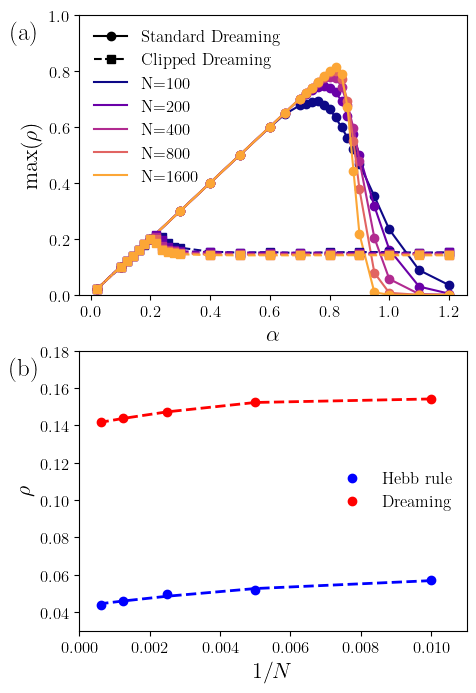

In [7]:
colors = cm.plasma(np.linspace(0, 1, 6))
fig, axes = plt.subplots(2, 1, figsize=(5, 8), sharex=False)

ax = axes[0]
# LaTeX panel label
ax.text(
    -0.1, 0.98, r"\textrm{(a)}",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=18
)

ax.plot(loads_unclipped,MaxRecRateDreamingUnclipped[0,:],marker='o', color=colors[0], label="")
ax.plot(loads_unclipped,MaxRecRateDreamingUnclipped[1,:],marker='o', color=colors[1], label="")
ax.plot(loads_unclipped,MaxRecRateDreamingUnclipped[2,:],marker='o', color=colors[2], label="")
ax.plot(loads_unclipped,MaxRecRateDreamingUnclipped[3,:],marker='o', color=colors[3], label="")
ax.plot(loads_unclipped,MaxRecRateDreamingUnclipped[4,:],marker='o', color=colors[4], label="")
ax.plot(loads_clipped,MaxRecRateDreamingClipped[0,:],marker='s', linestyle="dashed", color=colors[0], label="")
ax.plot(loads_clipped,MaxRecRateDreamingClipped[1,:],marker='s', linestyle="dashed", color=colors[1], label="")
ax.plot(loads_clipped,MaxRecRateDreamingClipped[2,:],marker='s', linestyle="dashed", color=colors[2], label="")
ax.plot(loads_clipped,MaxRecRateDreamingClipped[3,:],marker='s', linestyle="dashed", color=colors[3], label="")
ax.plot(loads_clipped,MaxRecRateDreamingClipped[4,:],marker='s', linestyle="dashed", color=colors[4], label="")
ax.plot([],[], marker='o', color='black', label="Standard Dreaming")
ax.plot([],[],marker='s', color='black', linestyle="dashed", label="Clipped Dreaming")
ax.plot([],[], color=colors[0], label="N=100")
ax.plot([],[], color=colors[1], label="N=200")
ax.plot([],[], color=colors[2], label="N=400")
ax.plot([],[], color=colors[3], label="N=800")
ax.plot([],[], color=colors[4], label="N=1600")
ax.set_ylim(0.,1.0)
ax.legend(frameon=False)
ax.set_xlabel(r"$\alpha$")
ax.set_ylabel(r"${\rm max}(\rho)$")

ax = axes[1]
# LaTeX panel label
ax.text(
    -0.1, 0.98, r"\textrm{(b)}",
    transform=ax.transAxes,
    ha="right", va="top",
    fontsize=18
)
ClippedHebbScaling = np.array([MaxRecRateHebbClipped[0,-1],MaxRecRateHebbClipped[1,-1],MaxRecRateHebbClipped[2,-1],MaxRecRateHebbClipped[3,-1],MaxRecRateHebbClipped[4,-1]])
ClippedDreamingScaling = np.array([MaxRecRateDreamingClipped[0,-9],MaxRecRateDreamingClipped[1,-9],MaxRecRateDreamingClipped[2,-9],MaxRecRateDreamingClipped[3,-9],MaxRecRateDreamingClipped[4,-9]])


# Model and fit 2nd order
def model(n, rho_inf, c1, c2):
    return rho_inf + c1 / (n) + c2/n**2.0
popt_hebb, pcov_hebb = curve_fit(model, Nloads[:], ClippedHebbScaling[:], p0=[0.1,1.0,1.0])  # initial guesses
popt_dream, pcov_dream = curve_fit(model, Nloads[:], ClippedDreamingScaling[:], p0=[0.1,1.0,1.0])  # initial guesses
rho_inf_hebb, c1_hebb, c2_hebb = popt_hebb
rho_inf_dream, c1_dream, c2_dream = popt_dream
print("Hebb:\nrho_inf = ", rho_inf_hebb)
print("c1  = ", c1_hebb)
print("c2  = ", c2_hebb)
print("Dreaming:\nrho_inf = ", rho_inf_dream)
print("c1  = ", c1_dream)
print("c2  = ", c2_dream)

ax.set_ylim(0.03,0.18)
hebb_fit_values = np.array([model(n,rho_inf_hebb,c1_hebb,c2_hebb) for n in Nloads])
dream_fit_values = np.array([model(n,rho_inf_dream,c1_dream,c2_dream) for n in Nloads])
ax.plot(1/np.array(Nloads),ClippedHebbScaling,"bo",label="Hebb rule")
ax.plot(1/np.array(Nloads),hebb_fit_values,color="blue",linestyle="dashed",linewidth=2)
ax.plot(1/np.array(Nloads),ClippedDreamingScaling,"ro",label="Dreaming")
ax.plot(1/np.array(Nloads),dream_fit_values,color="red",linestyle="dashed",linewidth=2)
ax.legend(frameon=False,loc='center right')

ax.set_xlim(0,0.011)
ax.set_xlabel(r"$1/N$")
ax.set_ylabel(r"$\rho$")
plt.savefig("figures/figure3.pdf", format="pdf", bbox_inches="tight")

# Figure 4

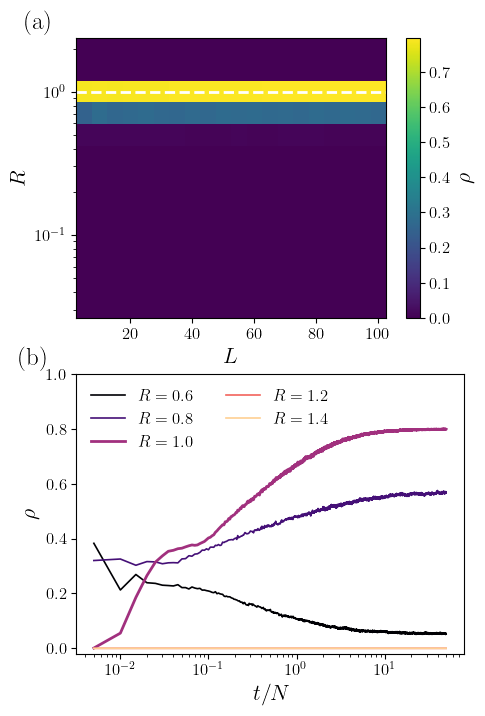

In [8]:
Nload = 200
load = 0.8
taol = 1.
taod = 10.
Instances = 50
A = 10000000
P = round(load*Nload)
Rs = 2**(1 - 0.5*np.arange(13))[::-1]
Batches = np.arange(5, 101, 5)
Dreams = np.round(Rs[:,None]*Batches[None,:]*taod/taol).astype(int)

def S_of(R):
    if R > 1.3:  return 2e4
    if R > 0.8:  return 4e5
    if R > 0.45: return 2e5
    return 1e5
CyclesGrid = np.ceil(np.array([S_of(R) for R in Rs])[:,None]/Batches[None,:]).astype(int)

RecRateDayDreamingUnclipped = dict()
FinalRecRateDayDreamingUnclipped = np.full((len(Rs),len(Batches)), np.nan)
MaxRecRateDayDreamingUnclipped = np.full((len(Rs),len(Batches)), np.nan)
for i,R in enumerate(Rs):
    for j,b in enumerate(Batches):
        d, C = Dreams[i,j], CyclesGrid[i,j]
        fn = f"data/UnclippedMixed/Recognition2percentGeneral_N_{Nload}_load_{load:.3f}_Dreams_{d}_Batches_{b}_taod_{taod:.2f}_taol_{taol:.2f}_Cycles_{C}_Ninstances_{Instances}_clippedA{A:.2f}.npz"
        try:
            f = np.load(fn)
        except FileNotFoundError:
            print("missing:", fn); continue
        cyc, RecRate = f['cycles'], f['matrix']                  # rho at log-spaced cycles
        RecRateDayDreamingUnclipped[(i,j)] = (cyc, RecRate)
        MaxRecRateDayDreamingUnclipped[i,j] = RecRate.max()
        FinalRecRateDayDreamingUnclipped[i,j] = RecRate[cyc >= C/2].mean()   # last factor 2 in cycles

# --- panel (a): heatmap in (L, R) -------------------------------------------
Le = np.append(Batches - 2.5, Batches[-1] + 2.5)
Re = np.append(Rs/2**0.25, Rs[-1]*2**0.25)
fig, axes = plt.subplots(2, 1, figsize=(5, 8))
ax = axes[0]
im = ax.pcolormesh(*np.meshgrid(Le, Re), FinalRecRateDayDreamingUnclipped, cmap="viridis")
ax.axhline(1, ls="--", color="white", lw=2)                     # equal contribution, D = L taod/taol
ax.set_yscale("log"); ax.set_xlabel(r"$L$"); ax.set_ylabel(r"$R$")
fig.colorbar(im, ax=ax, label=r"$\rho$")


axes[0].text(
    -0.07, 1.1, r"\textrm{(a)}",
    transform=axes[0].transAxes,
    ha="right", va="top",
    fontsize=18
)

# --- panel (b): rho vs epochs across the band, L = 80 ------------------------
# long runs at L = 80: 10000 cycles, 40 instances
Lb, Cb, Ni = 80, 10000, 40
band = [(0.6, 20), (0.8, 20), (1.0, 50), (1.2, 20), (1.4, 20)]
cols = plt.cm.magma(np.linspace(0, 0.9, len(band)))
for (R, ninst), col in zip(band, cols):
    d = int(round(R*Lb*taod/taol))
    fn = f"data/UnclippedMixed/Recognition2percentGeneral_N_{Nload}_load_{load:.3f}_Dreams_{d}_Batches_{Lb}_taod_{taod:.2f}_taol_{taol:.2f}_Cycles_{Cb}_Ninstances_{Ni}_clippedA{A:.2f}.npz"
    try:
        f = np.load(fn)
    except FileNotFoundError:
        print("missing:", fn); continue
    axes[1].plot(f['cycles']/Nload, f['matrix'], color=col, lw=2 if R == 1.0 else 1.2, label=fr"$R={R:.1f}$")

axes[1].text(
    -0.07, 1.1, r"\textrm{(b)}",
    transform=axes[1].transAxes,
    ha="right", va="top",
    fontsize=18
)
axes[1].set_xscale("log")
axes[1].set_ylim(-0.02, 1.0)
axes[1].set_xlabel(r"$t/N$")
axes[1].set_ylabel(r"$\rho$")
axes[1].legend(frameon=False, ncol=2, loc="upper left")
plt.savefig("figures/figure4.pdf", bbox_inches="tight")

# Figure 5

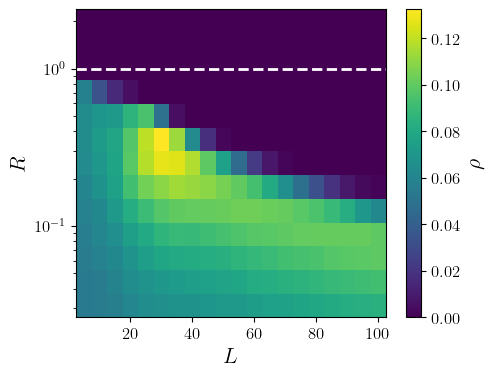

In [9]:
Nload = 200
Cycles = 50
load = 0.8
taol = 1.
taod = 10.
Instances = 50
A = 0.4
YAXIS = "R"          # "R": plot in (L, R = D taol/(L taod))    "D": plot in (L, D)
 
# --- the grid: same formula used to write gridfiles/ ------------------------
R  = 2**(1 - 0.5*np.arange(13))[::-1]                      # 0.03125 ... 2
Ls = np.arange(5, 101, 5)                                  # 5 ... 100
Ds = np.round(R[:,None]*Ls[None,:]*taod/taol).astype(int)  # D used in the runs
 
FinalRec = np.full(Ds.shape, np.nan)                       # NaN = not finished yet
for i in range(len(R)):
    for j, L in enumerate(Ls):
        fn = f"data/ClippedMixed/Recognition2percentGeneral_N_{Nload}_load_{load:.3f}_Dreams_{Ds[i,j]}_Batches_{L}_taod_{taod:.2f}_taol_{taol:.2f}_Cycles_{Cycles}_Ninstances_{Instances}_clippedA{A:.2f}.npz"
        try:
            RecRate = np.load(fn)['matrix']
        except FileNotFoundError:
            print("missing:", fn); continue
        FinalRec[i,j] = np.mean(RecRate[-10:])             # last 10 of 50 cycles
 
# --- cell edges: linear in L, geometric in R --------------------------------
Le = np.append(Ls - 2.5, Ls[-1] + 2.5)
Re = np.append(R/2**0.25, R[-1]*2**0.25)
Le, Re = np.meshgrid(Le, Re)
 
fig, ax = plt.subplots(1, 1, figsize=(5, 4))
if YAXIS == "D":
    im = ax.pcolormesh(Le, Re*Le*taod/taol, FinalRec, cmap="viridis")
    ax.plot(Ls, Ls*taod/taol, "--", color="white", lw=2)  # equal contribution
    ax.set_ylabel(r"$D$")
else:
    im = ax.pcolormesh(Le, Re, FinalRec, cmap="viridis")
    ax.axhline(1, ls="--", color="white", lw=2)            # equal contribution
    ax.set_ylabel(r"$R$")
ax.set_yscale("log")
fig.colorbar(im, label=r"$\rho$")
ax.set_xlabel(r"$L$")
fig.savefig(f"figures/figure5.pdf", bbox_inches="tight")